# 01 - Data cleaning: ISOT

This notebook loads the ISOT fake-news dataset and repeats the cleaning used by
`scripts/baseline_isot.py`. The goal is to see what the data looks like before
any model is trained.

In [1]:
import json, re, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import config

fake = pd.read_csv(config.ISOT_FAKE_PATH, usecols=["title", "text"])
true = pd.read_csv(config.ISOT_TRUE_PATH, usecols=["title", "text"])
fake["label"] = 0
true["label"] = 1
raw_fake = len(fake)
raw_true = len(true)
print("raw fake rows:", raw_fake)
print("raw true rows:", raw_true)
print("raw total:", raw_fake + raw_true)

raw fake rows: 23481
raw true rows: 21417
raw total: 44898


## Missing and empty text

Some rows have missing or empty `text`. They carry no information, so they are
dropped before anything else.

In [2]:
fake_empty = int(fake["text"].isna().sum()) + int((fake["text"].astype(str).str.strip() == "").sum())
true_empty = int(true["text"].isna().sum()) + int((true["text"].astype(str).str.strip() == "").sum())
print("empty/missing fake:", fake_empty, "true:", true_empty, "total:", fake_empty + true_empty)

fake = fake.dropna(subset=["text"]).copy()
true = true.dropna(subset=["text"]).copy()
fake["text"] = fake["text"].astype(str).str.strip()
true["text"] = true["text"].astype(str).str.strip()
fake = fake[fake["text"].str.len() > 0]
true = true[true["text"].str.len() > 0]
print("after dropping empty: fake", len(fake), "true", len(true))

empty/missing fake: 630 true: 1 total: 631


after dropping empty: fake 22851 true 21416


## Class balance and text length

Before deduplication we check how balanced the classes are and how long the
articles are. Very long or very short texts can hint at data problems.

class balance (0=Fake, 1=True):
label
0    22851
1    21416
Name: count, dtype: int64
text length (chars):
count    44267.000000
mean      2503.470283
std       2166.841665
min          5.000000
25%       1292.000000
50%       2208.000000
75%       3125.000000
max      51793.000000
Name: text, dtype: float64


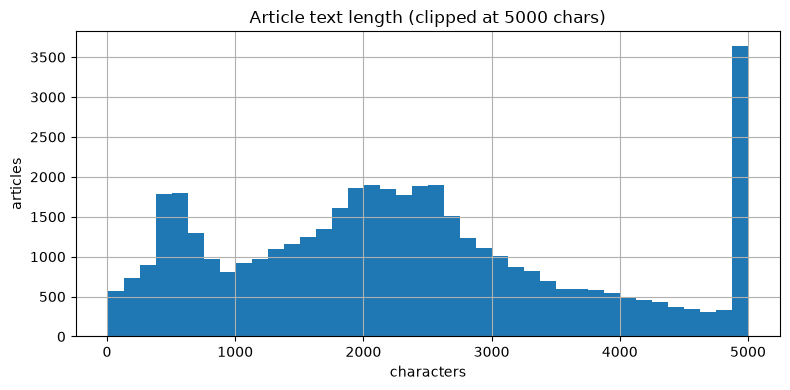

In [3]:
raw = pd.concat([fake, true], ignore_index=True)
print("class balance (0=Fake, 1=True):")
print(raw["label"].value_counts().sort_index())
print("text length (chars):")
print(raw["text"].str.len().describe())
plt.figure(figsize=(8, 4))
raw["text"].str.len().clip(upper=5000).hist(bins=40)
plt.title("Article text length (clipped at 5000 chars)")
plt.xlabel("characters")
plt.ylabel("articles")
plt.tight_layout()
plt.show()

## Wire-service datelines

Many `True` articles start with a dateline such as `WASHINGTON (Reuters) - `.
A classifier can learn that dateline instead of news style, so we count how
many articles carry one.

In [4]:
SOURCE_TAG_RE = re.compile(
     r"^\s*(?:[A-Za-z][A-Za-z .'\/-]{0,40}\s*)?"
     r"\((?:Reuters|AP|AFP)\)\s*[-\u2013\u2014]\s*",
     re.IGNORECASE,
 )
tagged = int(raw["text"].apply(lambda t: bool(SOURCE_TAG_RE.match(t))).sum())
print("rows with a leading wire-service dateline:", tagged)
print("share of all rows:", round(tagged / len(raw), 4))

rows with a leading wire-service dateline: 19451
share of all rows: 0.4394


## Deduplication

ISOT contains duplicate article text. We drop duplicates by `text`, keeping the
first occurrence, exactly as `scripts/baseline_isot.py` does.

In [5]:
before = len(raw)
dups = int(raw.duplicated(subset=["text"]).sum())
clean = raw.drop_duplicates(subset=["text"], keep="first").reset_index(drop=True)
print("rows before dedupe:", before)
print("duplicate text rows removed:", dups)
print("rows after dedupe:", len(clean))
print("fake after dedupe:", int((clean["label"] == 0).sum()))
print("true after dedupe:", int((clean["label"] == 1).sum()))

rows before dedupe: 44267
duplicate text rows removed: 5628
rows after dedupe: 38639
fake after dedupe: 17449
true after dedupe: 21190


## Before-and-after table

In [6]:
before_after = pd.DataFrame(
     {
         "step": ["raw rows", "after dropping empty text", "after deduplication"],
         "fake": [23481, 23481 - 0, int((clean["label"] == 0).sum())],
         "true": [21417, 21417 - 0, int((clean["label"] == 1).sum())],
         "total": [23481 + 21417, 23481 + 21417, len(clean)],
     }
 )
print(before_after.to_string(index=False))

                     step  fake  true  total
                 raw rows 23481 21417  44898
after dropping empty text 23481 21417  44898
      after deduplication 17449 21190  38639


## Assertions against results/baseline_metrics.json

The numbers above must match the tracked baseline metrics exactly.

In [7]:
metrics = json.loads((PROJECT_ROOT / "results" / "baseline_metrics.json").read_text(encoding="utf-8"))
ds = metrics["dataset"]
assert ds["fake_rows_raw"] == 23481
assert ds["true_rows_raw"] == 21417
assert ds["rows_dropped_empty_text"] == 631
assert ds["duplicate_text_rows_removed"] == 5628
assert ds["total_rows"] == 38639
assert ds["rows_with_leading_source_tag"] == 19243
assert int((clean["label"] == 0).sum()) == ds["fake_rows"]
assert int((clean["label"] == 1).sum()) == ds["true_rows"]
print("all assertions passed")

all assertions passed


## What I learned about the data

- ISOT is large but not clean: 631 empty rows and 5,628 duplicate rows had to be
  removed.
- The `True` class is slightly larger than `Fake` (21,190 vs 17,449 after
  cleaning).
- About half of all rows (19,243) carry a wire-service dateline, so a model can
  reach ~98% accuracy by reading the tag instead of the article. This is why the
  baseline is reported twice, with and without that dateline.

In [8]:
print("notebook 01 complete")

notebook 01 complete
